# Unit 6 seminar: K-Means clustering on iris, wine and weather data

**Task (from the seminar booklet):** study the module's K-Means demo, then carry out at least one of three
tasks. I did all three.

**About the module's demo.** It couldn't be run as supplied. It loads `Cust_Segmentation.csv` from a path on
the original author's own Windows drive (`C:\Users\sm21867\OneDrive - Cardiff Metropolitan University\...`),
and the file isn't provided with the module. Reading the code, there's also a logic slip worth knowing: it
standardises the data into `Clus_dataSet`, then trains K-Means on the original unscaled `X`, so the scaling
is never used. Task B below shows why that matters.

**Measuring agreement with the real labels.** K-Means never sees the labels. To check how well its clusters
line up with them afterwards, I use the **adjusted Rand index (ARI)** (Hubert and Arabie, 1985): 1 means the clusters match the labels
perfectly, 0 means no better than random grouping.

In [1]:
import numpy as np                                   # maths
import pandas as pd                                  # tables
import matplotlib.pyplot as plt                      # plotting
from sklearn.cluster import KMeans                   # the clustering algorithm
from sklearn.preprocessing import StandardScaler     # puts every column on the same scale (mean 0, sd 1)
from sklearn.metrics import silhouette_score, adjusted_rand_score   # cluster quality, and agreement with true labels
from sklearn.decomposition import PCA                # squashes many columns into 2 for plotting

def scan_k(X, ks, sample_size=None):                 # try several values of K and score each one
    # Inertia (sum of squared distances to the nearest centre) for the elbow plot,
    # and the silhouette score (Rousseeuw, 1987): how much closer each point is to its own cluster than to the next one.
    rows = []                                        # one result row per K
    for k in ks:                                     # each number of clusters to try
        km = KMeans(n_clusters=k, n_init=12, random_state=0).fit(X)   # 12 random starts, keep the best; seeded
        sil = silhouette_score(X, km.labels_, sample_size=sample_size, random_state=0) if k > 1 else np.nan   # undefined for K = 1
        rows.append((k, km.inertia_, sil))           # save the scores
    return pd.DataFrame(rows, columns=["k", "inertia", "silhouette"]).set_index("k")   # as a table

def plot_scan(scan, title):                          # draw the elbow and silhouette plots side by side
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))  # two plots side by side
    axes[0].plot(scan.index, scan.inertia, "o-"); axes[0].set_title(f"{title}: elbow"); axes[0].set_xlabel("k")  # elbow plot: inertia against K
    axes[1].plot(scan.index, scan.silhouette, "o-", color="tab:green"); axes[1].set_title(f"{title}: silhouette")  # silhouette against K
    axes[1].set_xlabel("k"); plt.tight_layout(); plt.show()  # label and draw

## Task A: iris

species
setosa        50
versicolor    50
virginica     50
   inertia  silhouette
k                     
1  600.000         NaN
2  223.732       0.580
3  140.966       0.459
4  114.616       0.390
5   91.192       0.348
6   80.212       0.326
7   71.801       0.335
8   63.013       0.343


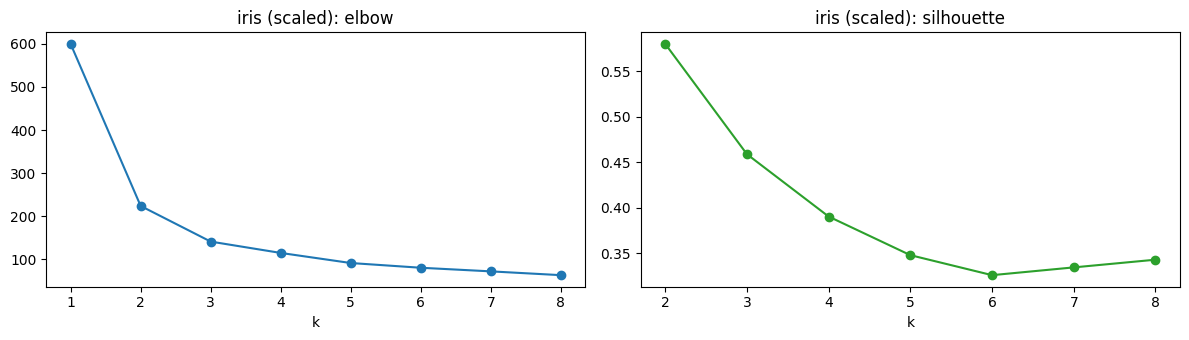

In [2]:
iris = pd.read_csv("iris.csv")                       # the module's iris file
X_iris = iris.drop(columns="species")          # species is the answer, so K-Means mustn't see it
print(iris.species.value_counts().to_string())       # 50 of each species
scan = scan_k(StandardScaler().fit_transform(X_iris), range(1, 9))   # score K = 1 to 8 on scaled data
print(scan.round(3))                                 # the table
plot_scan(scan, "iris (scaled)")                     # the plots

In [3]:
for label, data in [("unscaled", X_iris.values), ("scaled", StandardScaler().fit_transform(X_iris))]:   # both versions
    km = KMeans(n_clusters=3, n_init=12, random_state=0).fit(data)   # K = 3, as the task asks
    print(f"K=3, {label}: ARI vs species = {adjusted_rand_score(iris.species, km.labels_):.3f}")   # 1 = perfect match
    print(pd.crosstab(km.labels_, iris.species, rownames=["cluster"]), "\n")   # which species landed in which cluster

K=3, unscaled: ARI vs species = 0.730
species  setosa  versicolor  virginica
cluster                               
0             0          48         14
1            50           0          0
2             0           2         36 

K=3, scaled: ARI vs species = 0.620
species  setosa  versicolor  virginica
cluster                               
0             0          39         14
1            50           0          0
2             0          11         36 



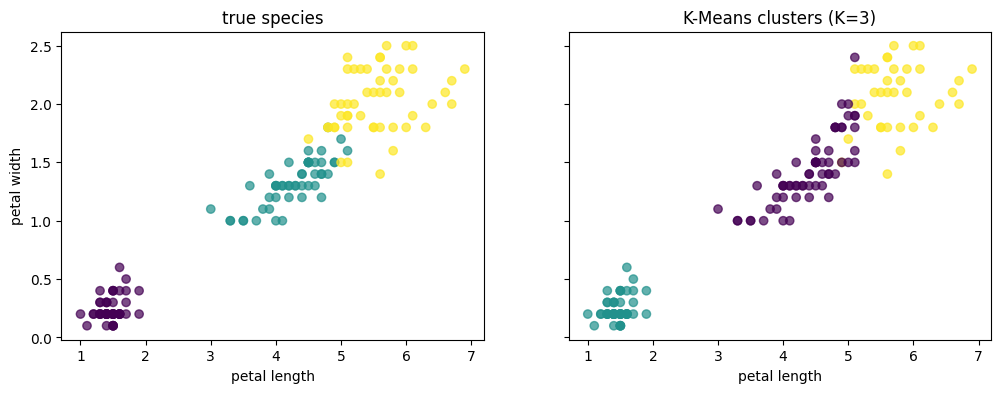

In [4]:
km = KMeans(n_clusters=3, n_init=12, random_state=0).fit(X_iris)   # the better (unscaled) version
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)       # truth vs clusters, side by side
for ax, colours, title in [(axes[0], iris.species.astype("category").cat.codes, "true species"),   # colour by species
                           (axes[1], km.labels_, "K-Means clusters (K=3)")]:                      # colour by cluster
    ax.scatter(iris.petal_length, iris.petal_width, c=colours, cmap="viridis", alpha=0.7)   # petal size separates them best
    ax.set_xlabel("petal length"); ax.set_title(title)  # label each plot
axes[0].set_ylabel("petal width"); plt.show()  # label and draw

## Task B: wine

In [5]:
wine = pd.read_csv("wine.csv")                       # the module's wine file
X_wine = wine.drop(columns="Wine")              # Wine (1, 2, 3) is the label
print(wine.Wine.value_counts().sort_index().to_string())   # how many wines of each type
print("\nThe columns are on very different scales:")  # heading for the ranges below
print(X_wine.agg(["min", "max"]).T.round(2).sort_values("max", ascending=False).head(4).to_string())   # biggest ranges
print("...")  # gap between the two lists
print(X_wine.agg(["min", "max"]).T.round(2).sort_values("max").head(3).to_string())   # smallest ranges

Wine
1    59
2    71
3    48

The columns are on very different scales:
            min      max
Proline  278.00  1680.00
Mg        70.00   162.00
Acl       10.60    30.00
Alcohol   11.03    14.83
...
                       min   max
Nonflavanoid.phenols  0.13  0.66
Hue                   0.48  1.71
Ash                   1.36  3.23


    inertia  silhouette
k                      
1  2314.000         NaN
2  1659.008       0.268
3  1277.928       0.285
4  1180.738       0.246
5  1110.365       0.203
6  1044.470       0.196
7   995.995       0.139
8   944.559       0.158


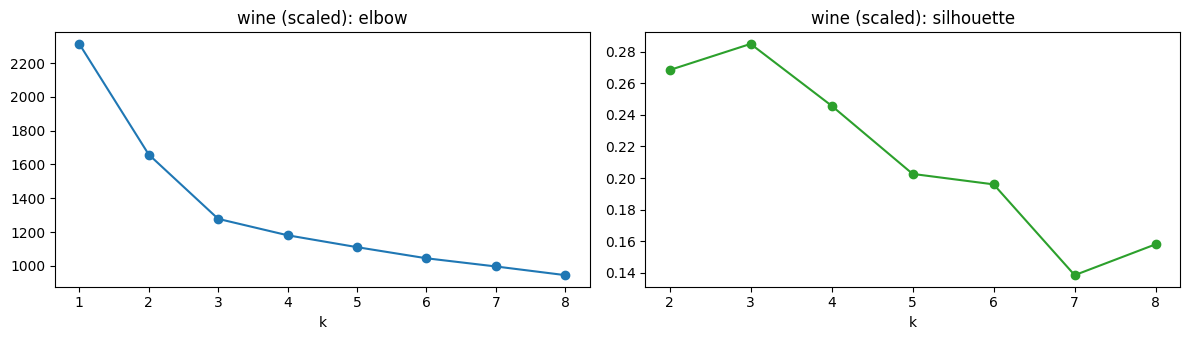

K=3, unscaled: ARI vs wine label = 0.371
wine      1   2   3
cluster            
0         0  50  19
1        46   1   0
2        13  20  29 

K=3, scaled: ARI vs wine label = 0.897
wine      1   2   3
cluster            
0         0  65   0
1         0   3  48
2        59   3   0 



In [6]:
scan = scan_k(StandardScaler().fit_transform(X_wine), range(1, 9))   # score K = 1 to 8 on scaled data
print(scan.round(3))  # the scores table
plot_scan(scan, "wine (scaled)")  # elbow and silhouette plots
for label, data in [("unscaled", X_wine.values), ("scaled", StandardScaler().fit_transform(X_wine))]:   # both versions
    km = KMeans(n_clusters=3, n_init=12, random_state=0).fit(data)   # K = 3, as the task asks
    print(f"K=3, {label}: ARI vs wine label = {adjusted_rand_score(wine.Wine, km.labels_):.3f}")  # agreement with the real wine types
    print(pd.crosstab(km.labels_, wine.Wine, rownames=["cluster"], colnames=["wine"]), "\n")   # clusters vs real types

In [7]:
# What is the unscaled version actually clustering on? Compare each column's share of the total variance.
share = (X_wine.var() / X_wine.var().sum()).sort_values(ascending=False)   # each column's variance as a share of the total
print("Share of total variance, unscaled:")  # heading
print((share.head(3) * 100).round(2).astype(str).add("%").to_string())   # the top three, as percentages

Share of total variance, unscaled:
Proline    99.77%
Mg          0.21%
Acl         0.01%


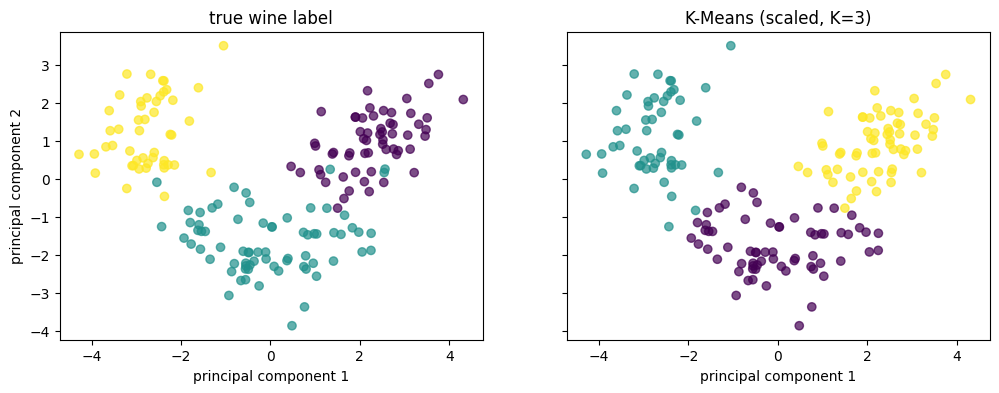

In [8]:
Xs = StandardScaler().fit_transform(X_wine)          # scaled wine data
pts = PCA(n_components=2).fit_transform(Xs)          # squash 13 columns to 2 so it can be plotted
km = KMeans(n_clusters=3, n_init=12, random_state=0).fit(Xs)   # cluster the scaled data
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)   # truth vs clusters
axes[0].scatter(pts[:, 0], pts[:, 1], c=wine.Wine, cmap="viridis", alpha=0.7); axes[0].set_title("true wine label")  # left: coloured by real type
axes[1].scatter(pts[:, 0], pts[:, 1], c=km.labels_, cmap="viridis", alpha=0.7); axes[1].set_title("K-Means (scaled, K=3)")  # right: coloured by cluster
for ax in axes: ax.set_xlabel("principal component 1")  # label both x axes
axes[0].set_ylabel("principal component 2"); plt.show()  # label and draw

## Task C: Australian weather

In [9]:
weather = pd.read_csv("weatherAUS.csv")              # the module's weather file
print(f"{len(weather):,} rows")  # size of the full file
num_cols = weather.columns.drop(["RainToday", "RainTomorrow"])   # Yes/No columns don't suit Euclidean distance
complete = weather.dropna(subset=num_cols)           # keep only days with every numeric column filled
print(f"{len(complete):,} rows with every numeric column filled ({len(complete) / len(weather):.0%})")  # how many days survive dropping gaps
print("Most-missing columns:", (weather[num_cols].isna().mean() * 100).round(1).sort_values(ascending=False).head(3).to_dict())  # the three columns with the most gaps, as %
Xw = StandardScaler().fit_transform(complete[num_cols])   # scale, because temperature, pressure and wind use different units

145,460 rows
120,381 rows with every numeric column filled (83%)
Most-missing columns: {'Pressure9am': 10.4, 'Pressure3pm': 10.3, 'WindGustSpeed': 7.1}


       inertia  silhouette
k                         
2  1069604.383       0.239
3   911738.388       0.231
4   829793.367       0.162
5   764241.499       0.173
6   703918.762       0.169


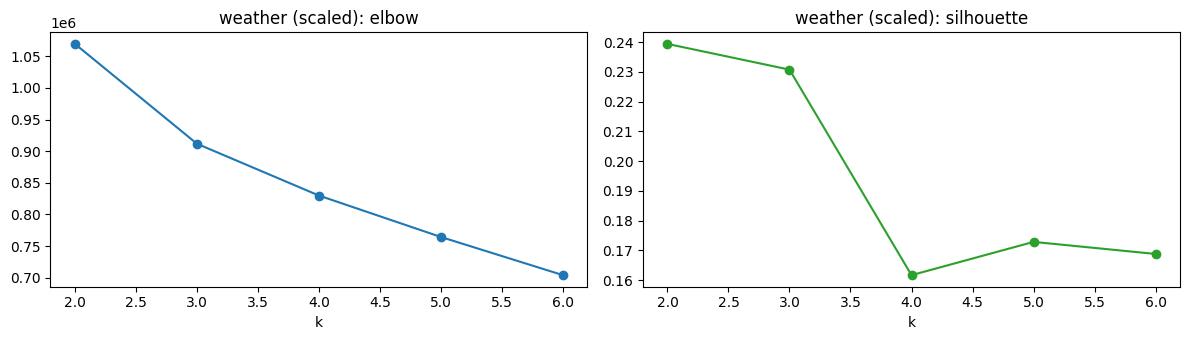

In [10]:
# Silhouette compares every point with every other point, so on ~120,000 rows it uses a 10,000-row sample.
scan = scan_k(Xw, range(2, 7), sample_size=10000)    # K = 2 to 6, as the task asks
print(scan.round(3))  # the scores table
plot_scan(scan, "weather (scaled)")  # elbow and silhouette plots

The first two principal components keep 60% of the variation.


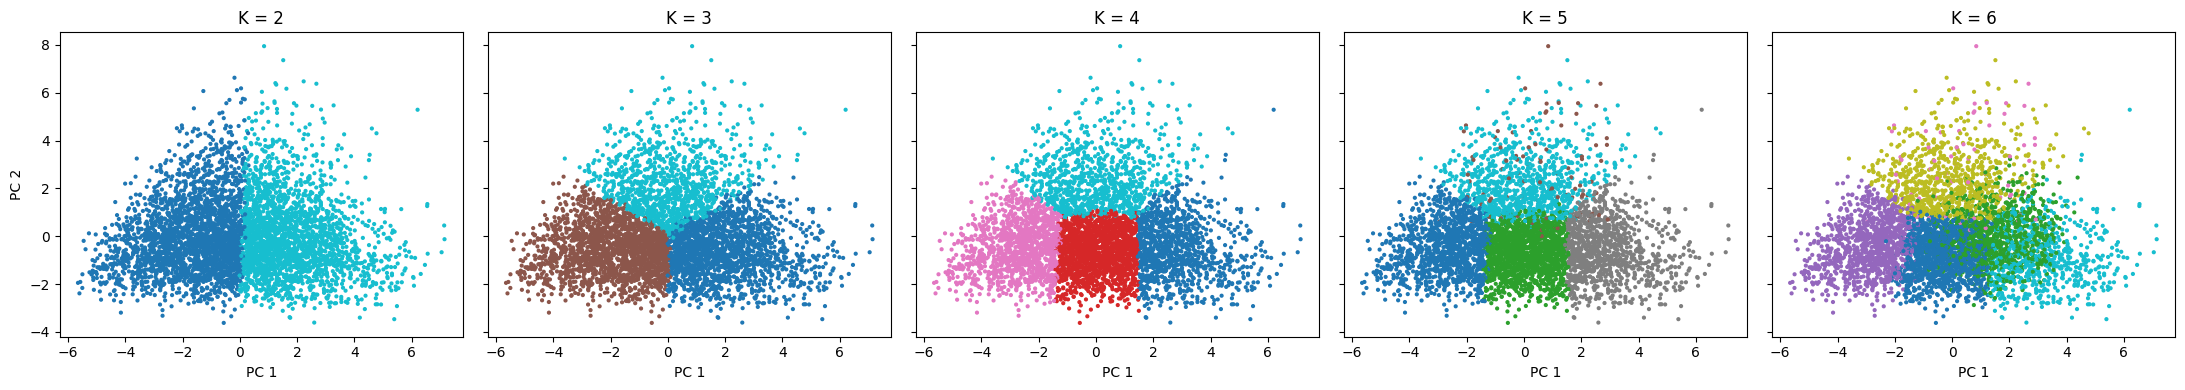

In [11]:
pca = PCA(n_components=2).fit(Xw)                    # find the 2 directions that keep the most variation
pts = pca.transform(Xw)                              # every day as a point in those 2 directions
print(f"The first two principal components keep {pca.explained_variance_ratio_.sum():.0%} of the variation.")  # how much the 2D picture loses
rng = np.random.default_rng(0)                       # seeded random generator
idx = rng.choice(len(Xw), 5000, replace=False)       # plot a sample so the points are visible
fig, axes = plt.subplots(1, 5, figsize=(22, 4), sharey=True)   # one plot per K
for ax, k in zip(axes, range(2, 7)):                 # K = 2 to 6
    labels = KMeans(n_clusters=k, n_init=12, random_state=0).fit_predict(Xw)   # cluster all the days
    ax.scatter(pts[idx, 0], pts[idx, 1], c=labels[idx], s=4, cmap="tab10")     # draw the sample, coloured by cluster
    ax.set_title(f"K = {k}"); ax.set_xlabel("PC 1")  # label each plot
axes[0].set_ylabel("PC 2"); plt.tight_layout(); plt.show()  # label and draw

In [12]:
# What do the K=3 clusters mean? Average weather per cluster, plus how often it rained the next day.
labels3 = KMeans(n_clusters=3, n_init=12, random_state=0).fit_predict(Xw)   # the K = 3 clustering
profile = complete.assign(cluster=labels3).groupby("cluster")[             # attach each day's cluster
    ["MaxTemp", "Rainfall", "Humidity3pm", "Pressure3pm", "WindGustSpeed"]].mean().round(1)   # average weather per cluster
profile["days"] = pd.Series(labels3).value_counts().sort_index().values   # how many days in each cluster
profile["rain next day"] = (complete.assign(cluster=labels3)              # RainTomorrow was never shown to K-Means
                            .groupby("cluster")["RainTomorrow"].apply(lambda s: (s == "Yes").mean())   # share of "Yes"
                            .map("{:.0%}".format))                       # as a percentage
print(f"Overall it rained the next day on {(complete.RainTomorrow == 'Yes').mean():.0%} of days.")   # the baseline to compare with
profile                                              # show the table

Overall it rained the next day on 22% of days.


,MaxTemp,Rainfall,Humidity3pm,Pressure3pm,WindGustSpeed,days,rain next day
cluster,,,,,,,
0,30.6,1.1,40.7,1011.7,40.8,45256,15%
1,19.0,1.2,54.0,1020.7,31.7,47695,16%
2,19.6,6.3,62.2,1011.6,53.7,27430,44%


## What I took from it


**Iris**
- **K-Means found the species well, but not perfectly.** At K = 3 the clusters agree with the real species at
  ARI 0.73. Setosa is separated perfectly, all 50 in one cluster. Versicolor and virginica overlap, and 16
  flowers land in the "wrong" cluster. The petal plot shows why: those two species really do merge into
  each other.
- **The scores would have picked the wrong K.** The silhouette is highest at K = 2 (0.58), not 3. Without the
  labels I'd have said "two groups", because versicolor and virginica look like one blob. Choosing K from
  the data alone isn't guaranteed to recover the real categories.
- **Scaling made iris worse (0.73 down to 0.62).** All four columns are already in centimetres. The petal
  measurements vary most, and they're the ones that separate the species. Scaling gives the less useful sepal
  width equal weight, which blurs things. So "always scale" is a habit, not a law. You need to know your
  columns.

**Wine**
- **Here scaling was everything: ARI 0.37 unscaled, 0.90 scaled.** Proline runs into the thousands while hue
  runs from about 0.5 to 1.7. Unscaled, Proline accounts for 99.8% of all the variation, so K-Means is
  really just sorting wines by Proline and ignoring the other 12 measurements. Scaled, it recovers the three
  cultivars almost exactly: only 6 of 178 wines are misplaced.
- This is exactly the slip in the module's demo, which scales the data and then clusters the unscaled copy.
- Both the elbow and the silhouette (best at K = 3, 0.285) point to the right answer on wine.

**Weather**
- **The data needed cleaning first.** RainToday and RainTomorrow are Yes/No, so they don't belong in a
  distance calculation. 17% of rows had a gap in some column, mostly pressure (10%), so I worked with the
  120,381 complete days.
- **There are no natural groups in weather.** Silhouette scores are low at every K (0.16 to 0.24), and the
  scatter plots show one continuous cloud that K-Means slices up rather than separate clumps. Weather changes
  gradually; it doesn't come in types.
- **The slices are still useful.** At K = 3 the clusters read like recognisable kinds of day: hot and dry
  (30.6°C max, 41% humidity), cool and settled (high pressure, light wind), and wet and windy (6.3 mm rain,
  strong gusts, low pressure). The wet and windy cluster was followed by rain the next day 44% of the time,
  against 22% overall. So even without "real" groups, clustering can summarise a huge table in a way a person
  can act on. That's the same idea as the customer segmentation in the module's demo.
- **A practical note:** the silhouette score compares every point with every other point. On 120,000 rows
  that's too slow, so I scored a 10,000-row sample. Big data changes what's practical, not just what's
  possible.